# 04 Exploratory Data Analysis


In [2]:
import sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.3f}".format)
FIG = "../reports/figures/"
RAW = "../data/raw/Dataset.xlsx"
from src.cleaning import CHANNEL_COLS, TARGET_COL, TOTAL_SPEND_COL, EXTERNAL_COLS
from src.preprocessing import HIGH_PROMO_PCT, HIGH_HOLIDAY_COUNT

df = pd.read_csv("../data/processed/mmm_cleaned.csv", parse_dates=["month"])
SHORT = {c: c.replace("_spend_lkr", "") for c in CHANNEL_COLS}
N = len(df)

# helper columns used only inside this notebook (the saved features are built in notebook 05)
df["year"] = df["month"].dt.year
df["month_num"] = df["month"].dt.month
df["t"] = np.arange(N)
for c, n in SHORT.items():
    df[n + "_share"] = df[c] / df[TOTAL_SPEND_COL]
df["ctr"] = df["clicks"] / df["impressions"]
df["cvr"] = df["conversions"] / df["clicks"]
df["cpc"] = df[TOTAL_SPEND_COL] / df["clicks"]
df["cost_per_conversion"] = df[TOTAL_SPEND_COL] / df["conversions"]
df["roas"] = df[TARGET_COL] / df[TOTAL_SPEND_COL]
df["high_promo"] = (df["promotion_discount_pct"] >= HIGH_PROMO_PCT).astype(int)
df["high_holiday"] = (df["public_holiday_count"] >= HIGH_HOLIDAY_COUNT).astype(int)

t_crit = stats.t.ppf(0.975, N - 2)
r_crit = t_crit / np.sqrt(N - 2 + t_crit ** 2)
print(f"{N} monthly rows. With this sample a correlation must exceed {r_crit:.2f} in absolute value to be significant at 5%.")

36 monthly rows. With this sample a correlation must exceed 0.33 in absolute value to be significant at 5%.


## 1. Sales trend

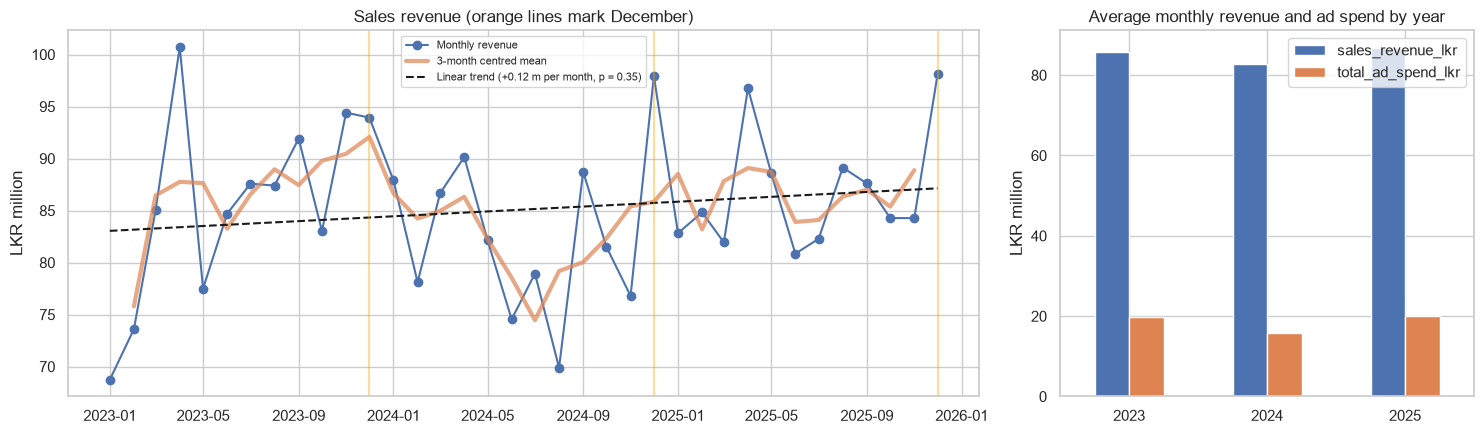

      sales_revenue_lkr  total_ad_spend_lkr
year                                       
2023             85.710              19.840
2024             82.770              15.860
2025             86.790              20.020

Revenue mean 85.1 m, SD 7.6 m, min 68.7 m, max 100.7 m
Linear trend: 0.117 m per month, R2 = 0.03, p = 0.35
Lag-1 autocorrelation of revenue: 0.08


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [2.2, 1]})
rev = df[TARGET_COL] / 1e6
ax[0].plot(df["month"], rev, marker="o", label="Monthly revenue")
ax[0].plot(df["month"], rev.rolling(3, center=True).mean(), lw=3, alpha=.7, label="3-month centred mean")
lr = stats.linregress(df["t"], rev)
ax[0].plot(df["month"], lr.intercept + lr.slope * df["t"], "k--", label=f"Linear trend ({lr.slope:+.2f} m per month, p = {lr.pvalue:.2f})")
for m in df.loc[df["month_num"] == 12, "month"]:
    ax[0].axvline(m, color="orange", alpha=.4)
ax[0].set(title="Sales revenue (orange lines mark December)", ylabel="LKR million")
ax[0].legend(fontsize=8)
yr = df.groupby("year")[[TARGET_COL, TOTAL_SPEND_COL]].mean() / 1e6
yr.plot.bar(ax=ax[1], rot=0)
ax[1].set(title="Average monthly revenue and ad spend by year", ylabel="LKR million", xlabel="")
plt.tight_layout()
plt.savefig(FIG + "04_01_sales_trend.png", dpi=150, bbox_inches="tight")
plt.show()
print(yr.round(2))
print(f"\nRevenue mean {rev.mean():.1f} m, SD {rev.std():.1f} m, min {rev.min():.1f} m, max {rev.max():.1f} m")
print(f"Linear trend: {lr.slope:.3f} m per month, R2 = {lr.rvalue ** 2:.2f}, p = {lr.pvalue:.2f}")
print("Lag-1 autocorrelation of revenue:", round(df[TARGET_COL].autocorr(1), 2))

## 2. Advertising spend by channel

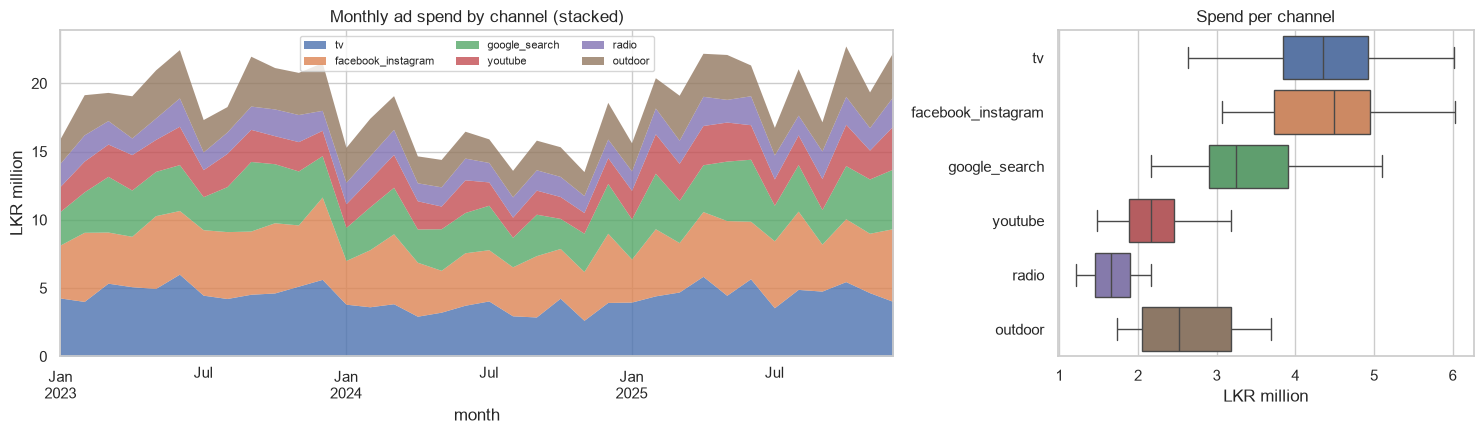

                    mean   std    cv   min   max  share_pct
tv                 4.360 0.860 0.200 2.640 6.020     23.470
facebook_instagram 4.400 0.770 0.180 3.070 6.030     23.680
google_search      3.320 0.720 0.220 2.160 5.100     17.850
youtube            2.220 0.450 0.200 1.480 3.180     11.950
radio              1.670 0.270 0.160 1.220 2.170      8.990
outdoor            2.610 0.630 0.240 1.730 3.690     14.060

Total spend by year (LKR m): {2023: 238.1, 2024: 190.3, 2025: 240.3}


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [2, 1]})
spend = df.set_index("month")[CHANNEL_COLS].rename(columns=SHORT) / 1e6
spend.plot.area(ax=ax[0], alpha=.8, linewidth=0)
ax[0].set(title="Monthly ad spend by channel (stacked)", ylabel="LKR million")
ax[0].legend(fontsize=8, ncol=3)
sns.boxplot(data=spend, ax=ax[1], orient="h")
ax[1].set(title="Spend per channel", xlabel="LKR million")
plt.tight_layout()
plt.savefig(FIG + "04_02_spend_by_channel.png", dpi=150, bbox_inches="tight")
plt.show()
summ = pd.DataFrame({"mean": spend.mean(), "std": spend.std(), "cv": spend.std() / spend.mean(),
                     "min": spend.min(), "max": spend.max(), "share_pct": spend.sum() / spend.sum().sum() * 100})
print(summ.round(2))
print("\nTotal spend by year (LKR m):", (df.groupby("year")[TOTAL_SPEND_COL].sum() / 1e6).round(1).to_dict())

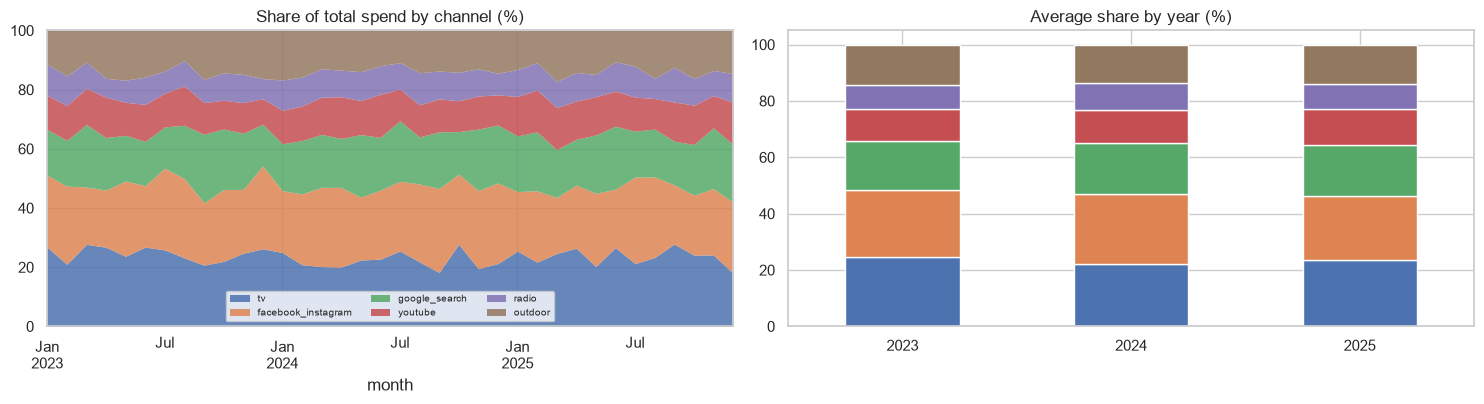

          tv  facebook_instagram  google_search  youtube  radio  outdoor
month                                                                   
2023  24.600              23.800         17.400   11.400  8.500   14.300
2024  22.100              24.900         18.100   11.700  9.400   13.800
2025  23.600              22.700         17.900   12.700  9.200   13.800


In [5]:
share_cols = [n + "_share" for n in SHORT.values()]
shares = df.set_index("month")[share_cols] * 100
shares.columns = list(SHORT.values())
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
shares.plot.area(ax=ax[0], alpha=.85, linewidth=0)
ax[0].set(title="Share of total spend by channel (%)", ylim=(0, 100))
ax[0].legend(fontsize=7, ncol=3, loc="lower center")
yearly_mix = shares.groupby(df.set_index("month").index.year).mean()
yearly_mix.plot.bar(stacked=True, ax=ax[1], rot=0, legend=False)
ax[1].set(title="Average share by year (%)", xlabel="")
plt.tight_layout()
plt.savefig(FIG + "04_03_channel_mix.png", dpi=150, bbox_inches="tight")
plt.show()
print(yearly_mix.round(1))

## 3. Correlation analysis

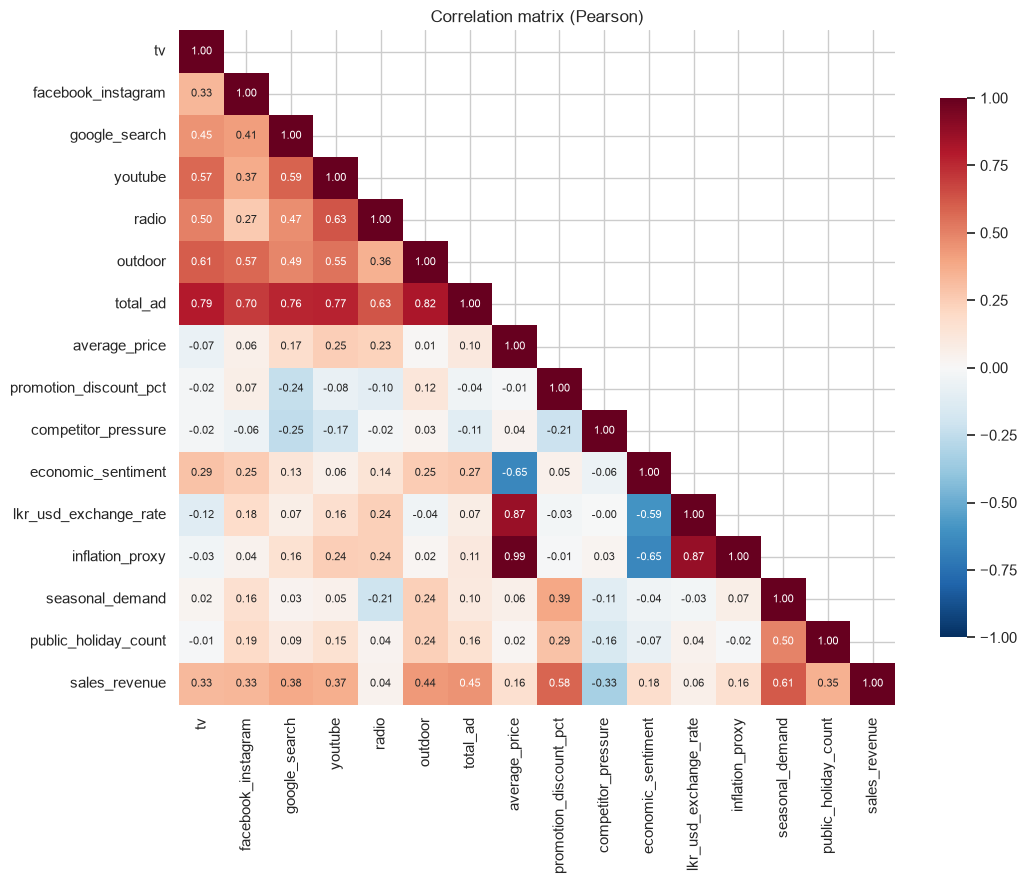

In [6]:
num_cols = CHANNEL_COLS + [TOTAL_SPEND_COL] + EXTERNAL_COLS + [TARGET_COL]
corr = df[num_cols].corr()
labels = [c.replace("_spend_lkr", "").replace("_0_100", "").replace("_index", "").replace("_lkr", "") for c in num_cols]
fig, ax = plt.subplots(figsize=(11, 9))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            xticklabels=labels, yticklabels=labels, ax=ax, annot_kws={"size": 8}, cbar_kws={"shrink": .8})
ax.set_title("Correlation matrix (Pearson)")
plt.tight_layout()
plt.savefig(FIG + "04_04_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

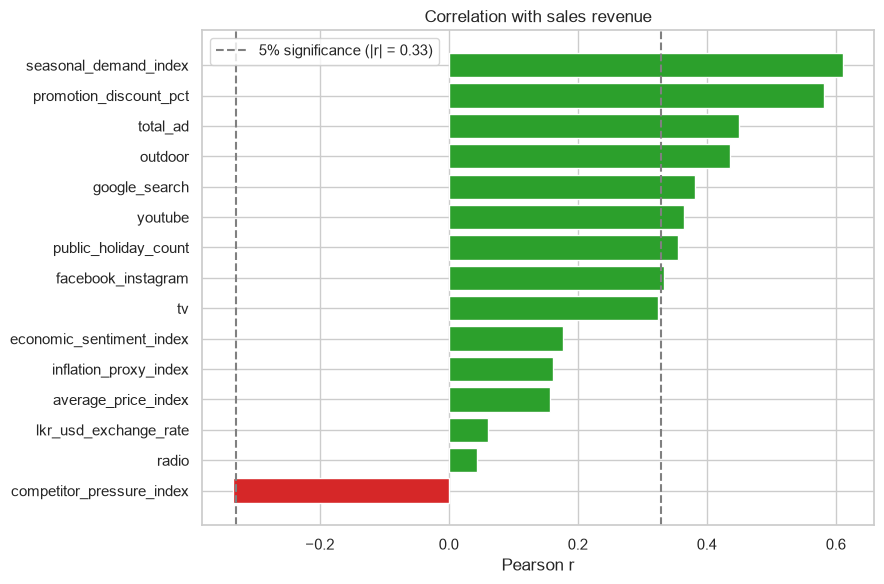

,pearson,spearman,p_value,significant_5pct
competitor_pressure_index_0_100,-0.335,-0.284,0.046,True
radio_spend_lkr,0.043,0.006,0.802,False
lkr_usd_exchange_rate,0.061,-0.001,0.724,False
average_price_index,0.157,0.118,0.361,False
inflation_proxy_index,0.162,0.122,0.344,False
economic_sentiment_index_0_100,0.177,0.183,0.302,False
tv_spend_lkr,0.325,0.273,0.053,False
facebook_instagram_spend_lkr,0.333,0.346,0.047,True
public_holiday_count,0.355,0.286,0.034,True
youtube_spend_lkr,0.365,0.321,0.029,True


In [7]:
predictors = num_cols[:-1]
cr = pd.DataFrame({
    "pearson": [stats.pearsonr(df[c], df[TARGET_COL])[0] for c in predictors],
    "spearman": [stats.spearmanr(df[c], df[TARGET_COL])[0] for c in predictors],
    "p_value": [stats.pearsonr(df[c], df[TARGET_COL])[1] for c in predictors],
}, index=predictors).sort_values("pearson")
cr["significant_5pct"] = cr["p_value"] < 0.05
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh([i.replace("_spend_lkr", "").replace("_0_100", "") for i in cr.index], cr["pearson"],
        color=["#d62728" if v < 0 else "#2ca02c" for v in cr["pearson"]])
ax.axvline(r_crit, ls="--", c="grey", label=f"5% significance (|r| = {r_crit:.2f})")
ax.axvline(-r_crit, ls="--", c="grey")
ax.set(title="Correlation with sales revenue", xlabel="Pearson r")
ax.legend()
plt.tight_layout()
plt.savefig(FIG + "04_05_correlation_with_revenue.png", dpi=150, bbox_inches="tight")
plt.show()
cr

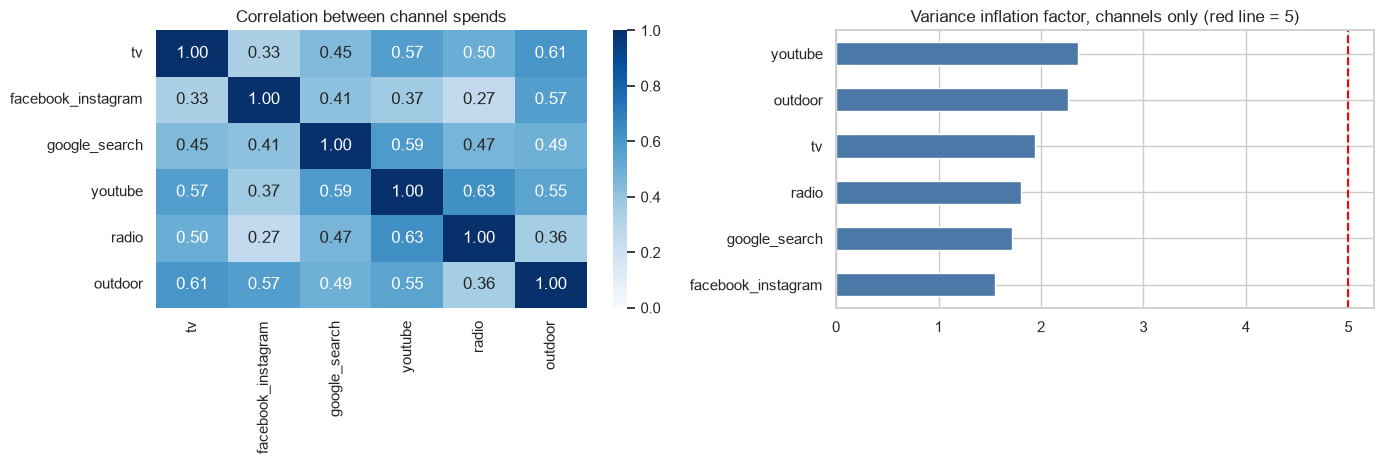

{'tv': 1.94, 'facebook_instagram': 1.55, 'google_search': 1.72, 'youtube': 2.36, 'radio': 1.81, 'outdoor': 2.26}

Correlation between the trending variables:
                                inflation_proxy_index  average_price_index      t  lkr_usd_exchange_rate  economic_sentiment_index_0_100
inflation_proxy_index                           1.000                0.990  1.000                  0.870                          -0.650
average_price_index                             0.990                1.000  0.990                  0.870                          -0.650
t                                               1.000                0.990  1.000                  0.870                          -0.670
lkr_usd_exchange_rate                           0.870                0.870  0.870                  1.000                          -0.590
economic_sentiment_index_0_100                 -0.650               -0.650 -0.670                 -0.590                           1.000


In [8]:
X = df[CHANNEL_COLS]
Z = (X - X.mean()) / X.std()
vif = {}
for c in Z:
    others = np.c_[np.ones(N), Z.drop(columns=c)]
    resid = Z[c] - others @ np.linalg.lstsq(others, Z[c], rcond=None)[0]
    vif[SHORT[c]] = 1 / (resid.var() / Z[c].var())
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
sns.heatmap(X.corr(), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax[0],
            xticklabels=list(SHORT.values()), yticklabels=list(SHORT.values()))
ax[0].set_title("Correlation between channel spends")
pd.Series(vif).sort_values().plot.barh(ax=ax[1], color="#4c78a8")
ax[1].axvline(5, ls="--", c="red")
ax[1].set(title="Variance inflation factor, channels only (red line = 5)")
plt.tight_layout()
plt.savefig(FIG + "04_06_channel_collinearity.png", dpi=150, bbox_inches="tight")
plt.show()
print({k: round(float(v), 2) for k, v in vif.items()})
trend_vars = ["inflation_proxy_index", "average_price_index", "t", "lkr_usd_exchange_rate", "economic_sentiment_index_0_100"]
print("\nCorrelation between the trending variables:")
print(df[trend_vars].corr().round(2))

## 4. Delayed effect of spend

Correlation between spend in month t-k and revenue in month t. The first three months are dropped for every lag so that all lags use the same 33 months.

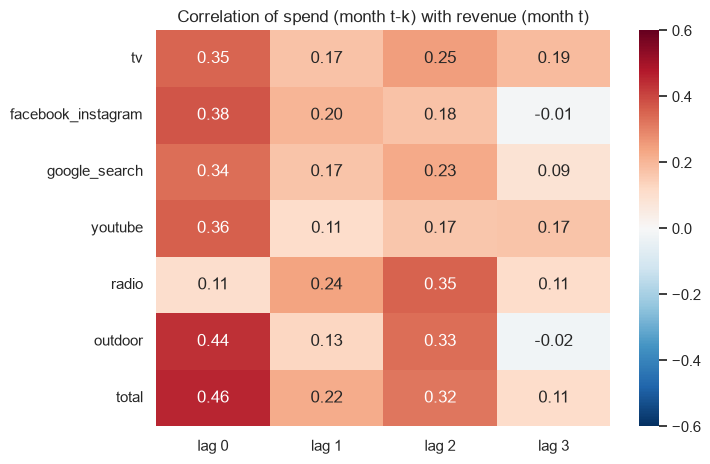

Lag with the highest correlation per channel: {'tv': 'lag 0', 'facebook_instagram': 'lag 0', 'google_search': 'lag 0', 'youtube': 'lag 0', 'radio': 'lag 2', 'outdoor': 'lag 0', 'total': 'lag 0'}


In [9]:
lag_range = range(0, 4)
lag_corr = pd.DataFrame(
    {SHORT.get(c, "total"): [df[c].shift(k).iloc[3:].corr(df[TARGET_COL].iloc[3:]) for k in lag_range]
     for c in CHANNEL_COLS + [TOTAL_SPEND_COL]},
    index=[f"lag {k}" for k in lag_range]).T
fig, ax = plt.subplots(figsize=(7.5, 4.8))
sns.heatmap(lag_corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-.6, vmax=.6, ax=ax)
ax.set_title("Correlation of spend (month t-k) with revenue (month t)")
plt.tight_layout()
plt.savefig(FIG + "04_07_lag_correlation.png", dpi=150, bbox_inches="tight")
plt.show()
print("Lag with the highest correlation per channel:", lag_corr.idxmax(axis=1).to_dict())

## 5. External factors

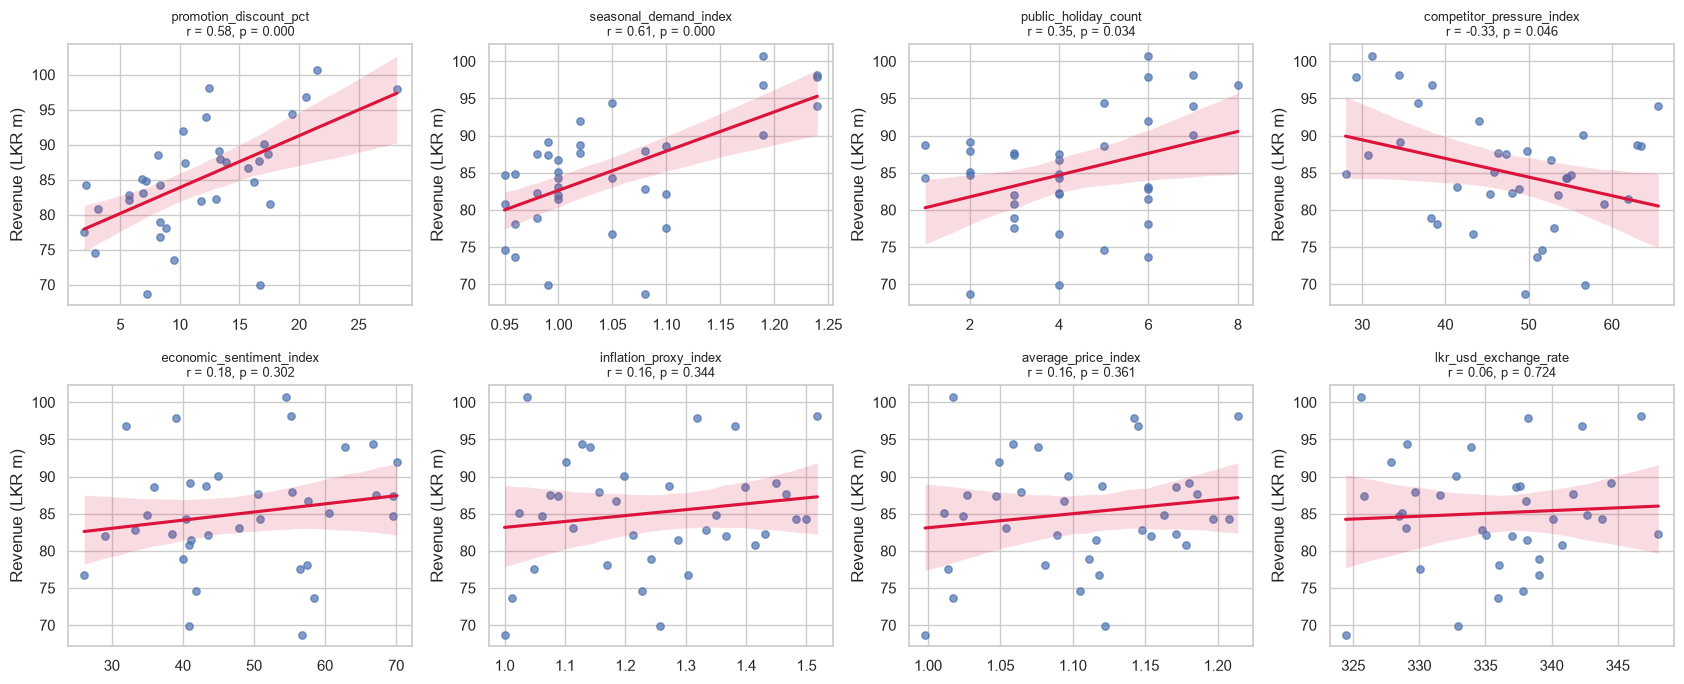

In [10]:
ext = ["promotion_discount_pct", "seasonal_demand_index", "public_holiday_count", "competitor_pressure_index_0_100",
       "economic_sentiment_index_0_100", "inflation_proxy_index", "average_price_index", "lkr_usd_exchange_rate"]
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, c in zip(axes.ravel(), ext):
    sns.regplot(x=df[c], y=df[TARGET_COL] / 1e6, ax=ax, scatter_kws={"s": 28, "alpha": .7}, line_kws={"color": "crimson"})
    r, p = stats.pearsonr(df[c], df[TARGET_COL])
    ax.set_title(f"{c.replace('_0_100', '')}\nr = {r:.2f}, p = {p:.3f}", fontsize=9)
    ax.set_ylabel("Revenue (LKR m)")
    ax.set_xlabel("")
plt.tight_layout()
plt.savefig(FIG + "04_08_external_factors.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
rows = []
for flag, label in [("high_promo", f"Promotion at least {HIGH_PROMO_PCT:g}%"), ("high_holiday", f"At least {HIGH_HOLIDAY_COUNT} public holidays")]:
    a, b = df[df[flag] == 1][TARGET_COL], df[df[flag] == 0][TARGET_COL]
    rows.append({"group": label, "months_flag_1": len(a), "mean_revenue_flag_1_m": a.mean() / 1e6,
                 "months_flag_0": len(b), "mean_revenue_flag_0_m": b.mean() / 1e6,
                 "difference_pct": (a.mean() / b.mean() - 1) * 100,
                 "welch_p_value": stats.ttest_ind(a, b, equal_var=False).pvalue})
pd.DataFrame(rows).set_index("group")

,months_flag_1,mean_revenue_flag_1_m,months_flag_0,mean_revenue_flag_0_m,difference_pct,welch_p_value
group,,,,,,
Promotion at least 15%,11,89.002,25,83.372,6.753,0.074
At least 6 public holidays,12,89.045,24,83.115,7.135,0.055


## 6. Seasonality

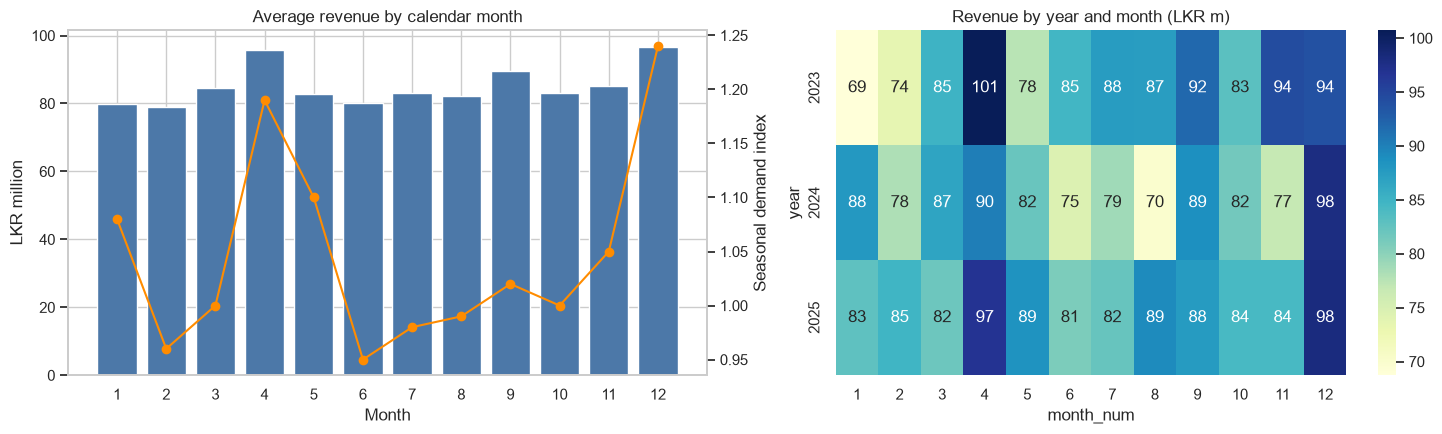

Highest average revenue: {12: 96.7, 4: 95.9, 9: 89.4}
Correlation of seasonal demand index with revenue: 0.61


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
monthly = df.groupby("month_num").agg(rev=(TARGET_COL, "mean"), idx=("seasonal_demand_index", "mean"))
ax[0].bar(monthly.index, monthly.rev / 1e6, color="#4c78a8")
ax[0].set(title="Average revenue by calendar month", xlabel="Month", ylabel="LKR million", xticks=range(1, 13))
twin = ax[0].twinx()
twin.plot(monthly.index, monthly.idx, "o-", color="darkorange")
twin.set_ylabel("Seasonal demand index")
twin.grid(False)
pivot = df.pivot_table(index="year", columns="month_num", values=TARGET_COL) / 1e6
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlGnBu", ax=ax[1])
ax[1].set_title("Revenue by year and month (LKR m)")
plt.tight_layout()
plt.savefig(FIG + "04_09_seasonality.png", dpi=150, bbox_inches="tight")
plt.show()
print("Highest average revenue:", (monthly.rev / 1e6).nlargest(3).round(1).to_dict())
print("Correlation of seasonal demand index with revenue:", round(df["seasonal_demand_index"].corr(df[TARGET_COL]), 2))

## 7. Spend against revenue

Each scatter plot shows a linear fit (red) and a log fit (green, dashed). If the log fit were clearly better it would suggest diminishing returns.

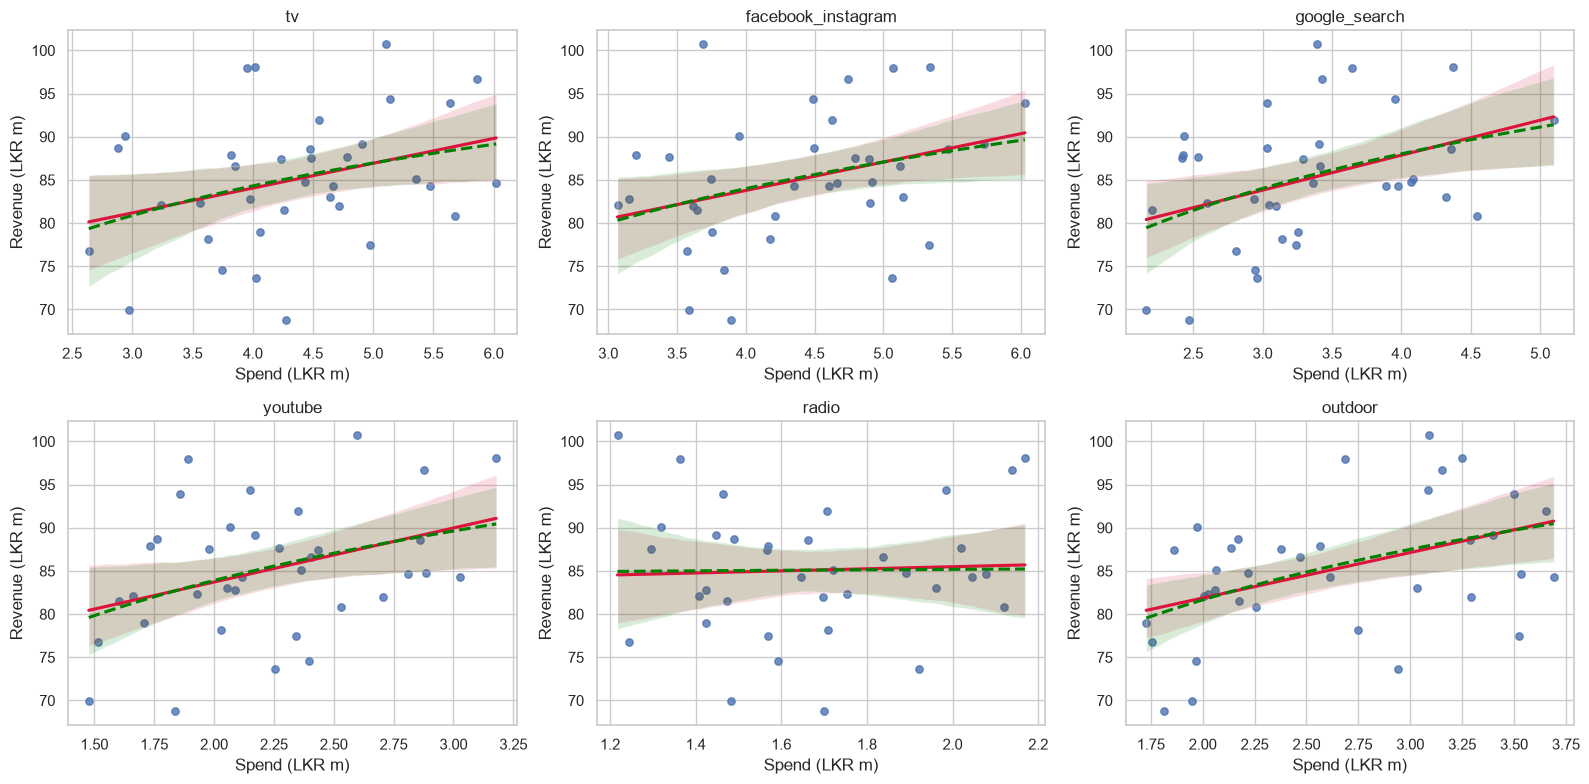

,r2_linear,r2_log,r2_gain_from_log
channel,,,
tv,0.106,0.104,-0.002
facebook_instagram,0.111,0.104,-0.006
google_search,0.146,0.155,0.009
youtube,0.133,0.139,0.005
radio,0.002,0.000,-0.002
outdoor,0.190,0.210,0.020


In [13]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
rows = []
for ax, c in zip(axes.ravel(), CHANNEL_COLS):
    x, y = df[c] / 1e6, df[TARGET_COL] / 1e6
    sns.regplot(x=x, y=y, ax=ax, scatter_kws={"s": 28}, line_kws={"color": "crimson"})
    sns.regplot(x=x, y=y, ax=ax, scatter=False, logx=True, line_kws={"color": "green", "ls": "--"})
    ax.set(title=SHORT[c], xlabel="Spend (LKR m)", ylabel="Revenue (LKR m)")
    rows.append({"channel": SHORT[c], "r2_linear": np.corrcoef(x, y)[0, 1] ** 2, "r2_log": np.corrcoef(np.log(x), y)[0, 1] ** 2})
plt.tight_layout()
plt.savefig(FIG + "04_10_spend_vs_revenue.png", dpi=150, bbox_inches="tight")
plt.show()
fits = pd.DataFrame(rows).set_index("channel")
fits["r2_gain_from_log"] = fits["r2_log"] - fits["r2_linear"]
fits

The four control variables explain R2 = 0.55 of the variance in revenue


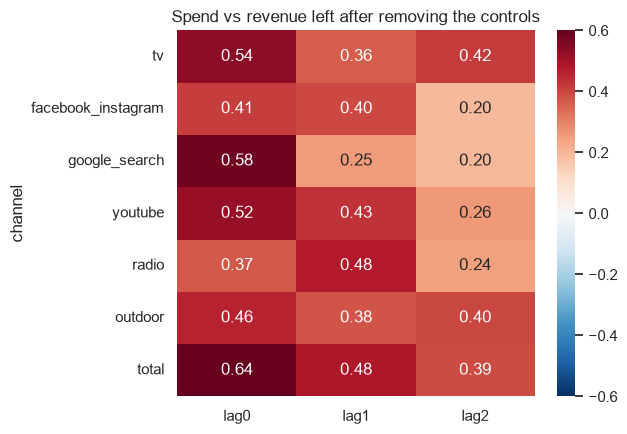

,lag0,lag1,lag2
channel,,,
tv,0.539,0.362,0.419
facebook_instagram,0.414,0.396,0.196
google_search,0.582,0.254,0.201
youtube,0.522,0.434,0.261
radio,0.371,0.477,0.244
outdoor,0.462,0.376,0.400
total,0.644,0.485,0.393


In [14]:
# Remove the part of revenue explained by seasonality, promotion, holidays and competitors,
# then correlate what is left with spend (current and lagged).
controls = df[["seasonal_demand_index", "promotion_discount_pct", "public_holiday_count", "competitor_pressure_index_0_100"]]
A = np.c_[np.ones(N), controls]
resid = df[TARGET_COL] - A @ np.linalg.lstsq(A, df[TARGET_COL], rcond=None)[0]
print(f"The four control variables explain R2 = {1 - resid.var() / df[TARGET_COL].var():.2f} of the variance in revenue")
rows = []
for c in CHANNEL_COLS + [TOTAL_SPEND_COL]:
    row = {"channel": SHORT.get(c, "total")}
    for k in (0, 1, 2):
        row[f"lag{k}"] = df[c].shift(k).iloc[3:].corr(resid.iloc[3:])
    rows.append(row)
partial = pd.DataFrame(rows).set_index("channel")
fig, ax = plt.subplots(figsize=(6.5, 4.5))
sns.heatmap(partial, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-.6, vmax=.6, ax=ax)
ax.set_title("Spend vs revenue left after removing the controls")
plt.tight_layout()
plt.savefig(FIG + "04_11_partial_correlation.png", dpi=150, bbox_inches="tight")
plt.show()
partial

Correlation of spend, funnel metrics, units and revenue:
                    total_ad_spend_lkr  impressions  clicks  conversions  units_sold  sales_revenue_lkr
total_ad_spend_lkr               1.000        0.460   0.370        0.410       0.280              0.450
impressions                      0.460        1.000   0.770        0.660      -0.090              0.070
clicks                           0.370        0.770   1.000        0.810       0.010              0.050
conversions                      0.410        0.660   0.810        1.000       0.160              0.290
units_sold                       0.280       -0.090   0.010        0.160       1.000              0.640
sales_revenue_lkr                0.450        0.070   0.050        0.290       0.640              1.000

Mean CTR 2.25%, mean CVR 3.65%, mean CPC 0.72 LKR, mean cost per conversion 22.2 LKR, mean ROAS 4.66 (min 3.69, max 6.14)


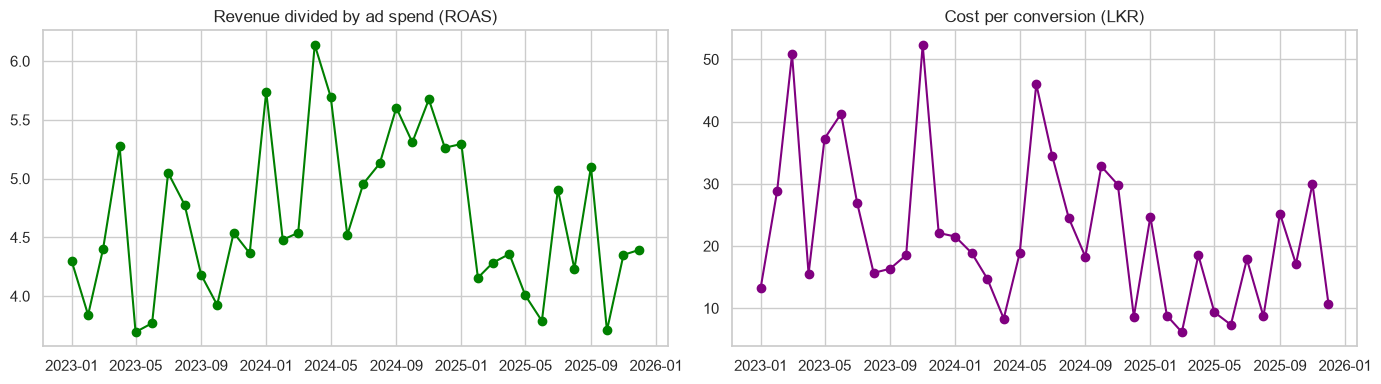

In [15]:
print("Correlation of spend, funnel metrics, units and revenue:")
print(df[[TOTAL_SPEND_COL, "impressions", "clicks", "conversions", "units_sold", TARGET_COL]].corr().round(2))
print("\nMean CTR %.2f%%, mean CVR %.2f%%, mean CPC %.2f LKR, mean cost per conversion %.1f LKR, mean ROAS %.2f (min %.2f, max %.2f)"
      % (df.ctr.mean() * 100, df.cvr.mean() * 100, df.cpc.mean(), df.cost_per_conversion.mean(), df.roas.mean(), df.roas.min(), df.roas.max()))
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(df["month"], df["roas"], marker="o", color="green")
ax[0].set(title="Revenue divided by ad spend (ROAS)")
ax[1].plot(df["month"], df["cost_per_conversion"], marker="o", color="purple")
ax[1].set(title="Cost per conversion (LKR)")
plt.tight_layout()
plt.savefig(FIG + "04_12_funnel_efficiency.png", dpi=150, bbox_inches="tight")
plt.show()

## Summary of findings

1. Sales. Monthly revenue averages LKR 85.1 m (SD 7.6 m, range 68.7 m to 100.7 m). There is no significant trend (+0.12 m per month, R2 = 0.03, p = 0.35). Yearly averages are 85.7 m (2023), 82.8 m (2024) and 86.8 m (2025). Revenue is highest in December (96.7 m on average) and April (95.9 m), followed by September (89.4 m).
2. Spend. Total spend averages LKR 18.6 m a month. Yearly totals are 238.1 m (2023), 190.3 m (2024) and 240.3 m (2025), so spend fell in 2024 and recovered in 2025. Facebook/Instagram (23.7%) and TV (23.5%) take the largest shares, radio (9.0%) the smallest. The mix is almost the same every year, which limits how well channel effects can be separated. No channel has outliers.
3. Correlation with revenue (n = 36, significant above about 0.33). Seasonal demand index 0.61 and promotion discount 0.58 are the strongest. Total ad spend is 0.45, outdoor 0.44, Google Search 0.38, YouTube 0.37, public holidays 0.36 and Facebook/Instagram 0.33 (p = 0.047). TV is 0.325 (p = 0.053) and radio 0.04. Competitor pressure is the only negative one (-0.335). Price, inflation, exchange rate and economic sentiment are not significant (0.06 to 0.18). Promotion and seasonality are almost uncorrelated with spend, so they are not strongly mixed up with advertising.
4. Collinearity. Correlation between channel spends ranges from 0.27 to 0.63 and the variance inflation factors are 1.6 to 2.4, which is acceptable. The trend variables are the problem: `inflation_proxy_index`, `average_price_index` and the month counter correlate 0.99 to 1.00, and the exchange rate correlates 0.87 with them. Only one of these should go into a model.
5. Delayed effect. For every channel except radio the correlation is highest in the same month. Radio is highest at a lag of 2 months. After removing the part of revenue explained by seasonality, promotion, holidays and competitor pressure (together R2 = 0.55), every channel still has a positive correlation with the remainder at lags 0 to 2 (0.37 to 0.58 at lag 0, total spend 0.64). Radio is highest at lag 1 (0.48). This fits a carry-over effect, but with 36 months and spend that moves slowly, the lags cannot be separated reliably. The decay rate should be estimated in the model.
6. Diminishing returns. A log fit is better than a linear fit only for Google Search, YouTube and outdoor, and by at most 0.02 in R2. Spend varies within a narrow range (coefficient of variation 16% to 24%), so saturation curves cannot be read from these plots and have to be estimated in the model.
7. Promotions and holidays. Months with a promotion of at least 15% (11 months) had 6.8% higher revenue than other months (p = 0.074). Months with at least 6 public holidays (12 months) had 7.1% higher revenue (p = 0.055). Both differences are suggestive, not conclusive.
8. Funnel. Average click-through rate is 2.25%, conversion rate 3.65%, cost per click 0.72 LKR, cost per conversion 22.2 LKR and revenue per rupee of ad spend 4.66 (range 3.69 to 6.14). Impressions (0.07) and clicks (0.05) are almost unrelated to revenue and conversions are weak (0.29). These figures describe the funnel but should not be model inputs.

## Recommendations for modelling

* Include seasonality, promotion, holiday and competitor variables next to the media variables. Together they explain more of revenue than any single channel.
* Use only one of `inflation_proxy_index`, `average_price_index` and the time counter.
* Leave out `impressions`, `clicks`, `conversions`, `total_ad_spend_lkr` and any column built from revenue (see the modelling_role column in `reports/data_dictionary.md`).
* Estimate adstock and saturation inside the model. The helpers `geometric_adstock` and `hill_saturation` are in `src/preprocessing.py`.
* With 36 rows, use regularisation or priors and validate with the walk-forward folds from notebook 05. Keep the last 6 months for the final test.